# Loading Pre-Trained Weights


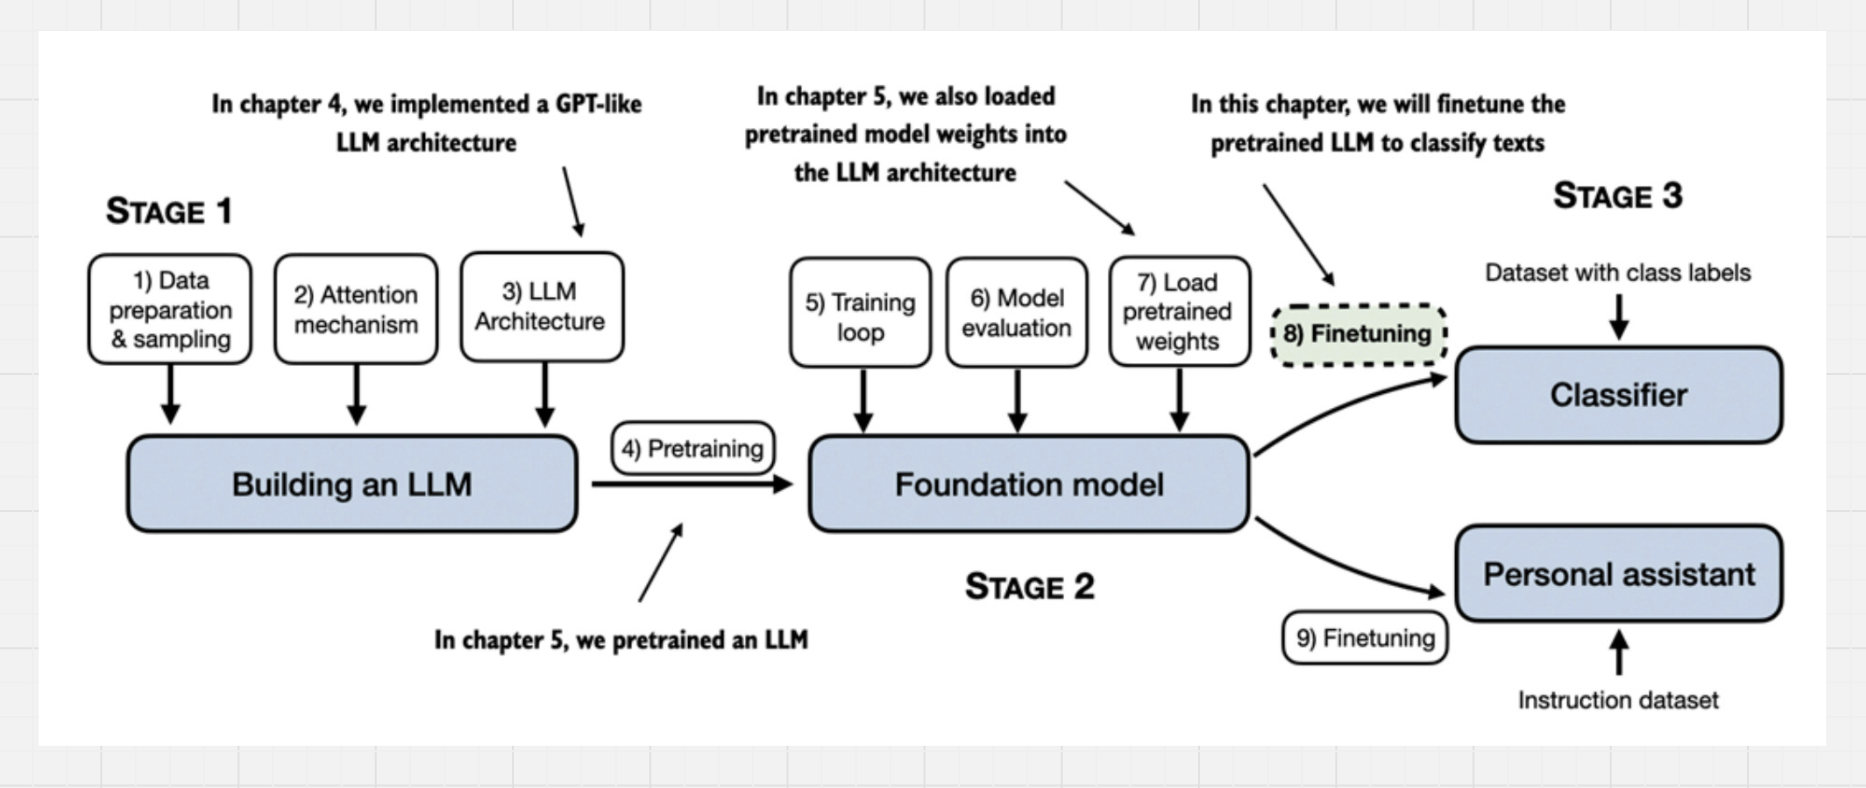


In [1]:
pip install tensorflow tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import tensorflow as tf
import tqdm

In [3]:
print("TensorFlow version:", tf.__version__)
print("tqdm version:", tqdm.__version__)

TensorFlow version: 2.22.0-rc0
tqdm version: 4.70.1


In [5]:
from gpt_download3 import download_and_load_gpt2

In [8]:
settings,params = download_and_load_gpt2(model_size="124M", models_dir="gpt2" )

checkpoint: 100%|████████████████████████████████████████████████████████████████████| 77.0/77.0 [00:00<00:00, 550kB/s]


encoder.json: 100%|████████████████████████████████████████████████████████████████| 1.04M/1.04M [00:02<00:00, 484kB/s]


hparams.json: 100%|██████████████████████████████████████████████████████████████████| 90.0/90.0 [00:00<00:00, 433kB/s]


model.ckpt.data-00000-of-00001: 100%|████████████████████████████████████████████████| 498M/498M [23:50<00:00, 348kB/s]


model.ckpt.index: 100%|███████████████████████████████████████████████████████████| 5.21k/5.21k [00:00<00:00, 27.5MB/s]


model.ckpt.meta: 100%|██████████████████████████████████████████████████████████████| 471k/471k [00:07<00:00, 61.2kB/s]


vocab.bpe: 100%|████████████████████████████████████████████████████████████████████| 456k/456k [00:05<00:00, 83.4kB/s]


In [9]:
print("Settings:", settings)
print("Parameter dictionary keys:", params.keys())

Settings: {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}
Parameter dictionary keys: dict_keys(['blocks', 'b', 'g', 'wpe', 'wte'])


In [10]:
print(params["wte"])
print("Token embedding weight tensor dimensions:", params["wte"].shape)

[[-0.11010301 -0.03926672  0.03310751 ... -0.1363697   0.01506208
   0.04531523]
 [ 0.04034033 -0.04861503  0.04624869 ...  0.08605453  0.00253983
   0.04318958]
 [-0.12746179  0.04793796  0.18410145 ...  0.08991534 -0.12972379
  -0.08785918]
 ...
 [-0.04453601 -0.05483596  0.01225674 ...  0.10435229  0.09783269
  -0.06952604]
 [ 0.1860082   0.01665728  0.04611587 ... -0.09625227  0.07847701
  -0.02245961]
 [ 0.05135201 -0.02768905  0.0499369  ...  0.00704835  0.15519823
   0.12067825]]
Token embedding weight tensor dimensions: (50257, 768)


## GPT MODEL Function

In [11]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader

In [12]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 256, # Context length we are going to look 1024 number of tokens at once
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

In [13]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0 ,"d_out is not divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out//num_heads

        self.W_query = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_key = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_value = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.dropout = torch.nn.Dropout(dropout)
        self.register_buffer("mask",
                            torch.triu(torch.ones(context_length,context_length),diagonal=1))
        self.out_proj = torch.nn.Linear(d_out,d_out)

    def forward(self,x):
        b,num_tokens,d_in = x.shape

        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        values = self.W_value(x)
        queries = self.W_query(x)

         # Reshape to split d_out into (num_heads, head_dim)
        keys = keys.view(b,num_tokens,self.num_heads,self.head_dim)
        values = values.view(b,num_tokens,self.num_heads,self.head_dim)
        queries = queries.view(b,num_tokens,self.num_heads,self.head_dim)

        # transpose the 1,2 to get b,num_heads,num_tokens,head_dim for the calculation of attn_score
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        atten_score = queries @ keys.transpose(-2,-1)
        atten_score.masked_fill(self.mask.bool()[:num_tokens,:num_tokens],-torch.inf)

        atten_weights = torch.softmax(atten_score/keys.shape[-1]**0.5,dim=-1)
        atten_weights = self.dropout(atten_weights)

        context_vec = (atten_weights@values).transpose(1,2) # transpose to get back to the originl form

        # combine the head and the head dim 
        context_vec = context_vec.contiguous().view(b,num_tokens,self.d_out)
        context_vec = self.out_proj(context_vec)

        return context_vec

In [14]:
# layer normalization class : alpha(X-mean/root(var)+epsilon) + beta 

class LayerNormalization(nn.Module):
    def __init__(self,emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim)) # alpha
        self.shift = nn.Parameter(torch.zeros(emb_dim)) # beta
    def forward(self,x):
        mean = x.mean(dim=-1,keepdim=True)
        var = x.var(dim=-1,keepdim=True,unbiased=False)
        norm_x = (x-mean)/torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

In [15]:
# gelu class
class GELU(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self,x):
        return 0.5*x*(1+torch.tanh(
            torch.sqrt(torch.tensor(2.0/torch.pi))*
            (x + 0.44715 * torch.pow(x,3))
        ))

In [16]:
# FeedForward NN : embed --> 4*embed ---> embed 
class FeedForward(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg['emb_dim'],4*cfg['emb_dim']),
            GELU(),
            nn.Linear(4*cfg['emb_dim'],cfg['emb_dim'])
        )
    def forward(self,x):
        return self.layers(x)

print(GPT_CONFIG_124M["emb_dim"])

768


In [17]:
class TransformerBlock(nn.Module):
    def __init__(self,cfg):
        super().__init__()
        self.att = MultiHeadAttention(
                            d_in = cfg["emb_dim"],
                            d_out = cfg["emb_dim"],
                            context_length = cfg["context_length"],
                            dropout = cfg["drop_rate"],
                            num_heads = cfg["n_heads"],
                            qkv_bias = cfg[ "qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNormalization(cfg["emb_dim"])
        self.norm2 = LayerNormalization(cfg["emb_dim"])
        self.drop_shortcuts = torch.nn.Dropout(cfg['drop_rate'])

    def forward(self,x):
        # shortcut connnection for the MultiHead Attention Block
        shortcut = x # store the x value to use it in th shotcut connections 
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcuts(x)
        x = x + shortcut

        # shortcut connection for the feed forward block 
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcuts(x)
        x = x + shortcut

        return x


In [18]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        
        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        
        self.final_norm = LayerNormalization(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

### Updating the Confiuration of th GPT Model

In [19]:
# we wil update the gpt config to context_size --> 1024 and bias=true

# Define model configurations in a dictionary for compactness
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

# Copy the base configuration and update with specific model settings
model_name = "gpt2-small (124M)"  # Example model name
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])

In [20]:
NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})
gpt = GPTModel(NEW_CONFIG)
gpt.eval();

In [21]:
import tiktoken

def text_to_token(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # add batch dimension
    return encoded_tensor

def token_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) # remove batch dimension
    return tokenizer.decode(flat.tolist())

tokenizer = tiktoken.get_encoding("gpt2")

Next, we define a load_weights_into_gpt function that loads the weights from the params dictionary into a GPTModel instance gpt:

Step 1: Setting the model's positional and token embedding weights to those specified in params.

Step 2: Iterate over each transformer block in the model.

Step 3: The np.split function is used to divide the attention and bias weights into three equal parts for the query, key, and value components.

Step 4: The original GPT-2 model by OpenAI reused the token embedding weights in the output layer to reduce the total number of parameters, which is a concept known as weight tying.

## Assigining the pre-trained weights of the GPT-2 (124M param) to out Model

In [22]:
import numpy as np

def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params['wpe'])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params['wte'])
    
    for b in range(len(params["blocks"])):
        q_w, k_w, v_w = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight, 
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias, 
            params["blocks"][b]["attn"]["c_proj"]["b"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight, 
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias, 
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight, 
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias, 
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale, 
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift, 
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale, 
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift, 
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])


In [23]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))

In [24]:
# load the data to the model gpt
load_weights_into_gpt(gpt, params)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpt.to(device)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNormalization()
      (norm2): LayerNormalization()
      (drop_shortcuts): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): L

### Generate Fucntion 

In [25]:
def generate(model,idx,max_new_tokens,context_size,temperature=0.0,top_k=None,eos_id=None):
    # get the logits and focus on the last step
    for _ in range(max_new_tokens):
        idx_cond = idx[:,-context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:,-1,:]

        # filter logits with top k sampling 
        if top_k is not None:
            # keep only the top k values --> torch.topk= = logits_top , logits_ids
            top_logits, _ = torch.topk(logits,top_k)
            min_val = top_logits[:,-1]
            # set the logtis to -inf whose value is less then min_val_logits
            logits = torch.where(logits<min_val , torch.tensor(float("-inf")).to(logits.device),logits)

        # apply temp scalling 
        if temperature > 0.0:
            logits = logits/temperature
            # apply softmax  to get probabilities
            probas = torch.softmax(logits,dim=-1) #(batch_size,context_length)
            # aply multinomial sample from the distribution 
            idx_next = torch.multinomial(probas,num_samples=1)#(batch_size,1)
            
        # Otherwise same as before: get idx of the vocab entry with the highest logits value
        else:
            idx_next = torch.argmax(logits,dim=-1,keepdim=True)
            
        if idx_next==eos_id: # # Stop generating early if end-of-sequence token is encountered and eos_id is specified
            break
    
    
        idx = torch.cat((idx,idx_next),dim=1)

    return idx 

In [26]:
torch.manual_seed(123)

token_ids = generate(
    model=gpt,
    idx=text_to_token("Every effort moves you", tokenizer).to(device),
    max_new_tokens=25,
    context_size=NEW_CONFIG["context_length"],
    top_k=50,
    temperature=1.5
)

print("Output text:\n", token_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you an incredibly well by it are actually is by us







beef on that hot dogs…


# FINETUNING FOR CLASSIFICATION Spam/Non-Spam Dataset MODEL

## DOWNLOADING DATASET

In [27]:
import urllib.request
import ssl
import zipfile
import os
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extracted_path = "sms_spam_collection"
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"

def download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path):
    if data_file_path.exists():
        print(f"{data_file_path} already exists. Skipping download and extraction.")
        return

    # Create an unverified SSL context
    ssl_context = ssl._create_unverified_context()

    # Downloading the file
    with urllib.request.urlopen(url, context=ssl_context) as response:
        with open(zip_path, "wb") as out_file:
            out_file.write(response.read())

    # Unzipping the file
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extracted_path)

    # Add .tsv file extension
    original_file_path = Path(extracted_path) / "SMSSpamCollection"
    os.rename(original_file_path, data_file_path)
    print(f"File downloaded and saved as {data_file_path}")

download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)

sms_spam_collection/SMSSpamCollection.tsv already exists. Skipping download and extraction.


After executing the preceding code, the dataset is saved as a tab-separated text file, SMSSpamCollection.tsv, in the sms_spam_collection folder.

We can load it into a pandas DataFrame as follows:

In [28]:
import pandas as pd

df = pd.read_csv(data_file_path, sep="\t", header=None, names=["Label", "Text"])
df

,Label,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [29]:
print(df["Label"].value_counts())

Label
ham     4825
spam     747
Name: count, dtype: int64


In [30]:
# create the balanced dataset 
def create_balanced_dataset(df):
    
    # Count the instances of "spam"
    num_spam = df[df["Label"] == "spam"].shape[0]
    
    # Randomly sample "ham" instances to match the number of "spam" instances
    ham_subset = df[df["Label"] == "ham"].sample(num_spam, random_state=123)
    
    # Combine ham "subset" with "spam"
    balanced_df = pd.concat([ham_subset,df[df["Label"] == "spam"]])

    return balanced_df

balanced_df = create_balanced_dataset(df)
print(balanced_df["Label"].value_counts())

Label
ham     747
spam    747
Name: count, dtype: int64


In [31]:
balanced_df["Label"] = balanced_df["Label"].replace({"ham": 0, "spam": 1})

<div class="alert alert-block alert-warning">
    
**This process is similar to converting text into token IDs.

However, instead of using the GPT vocabulary, which consists of more than 50,000 words, we are dealing with just two token IDs: 0 and 1.  **
</div>


<div class="alert alert-block alert-warning">
    
**We create a random_split function to split the dataset into three parts: 70% for training, 10% for validation, and 20% for testing.**
</div>


In [32]:
def random_split(df, train_frac, validation_frac):
    # Shuffle the entire DataFrame
    df = df.sample(frac=1, random_state=123).reset_index(drop=True)

    # Calculate split indices
    train_end = int(len(df) * train_frac)
    validation_end = train_end + int(len(df) * validation_frac)

    # Split the DataFrame
    train_df = df[:train_end]
    validation_df = df[train_end:validation_end]
    test_df = df[validation_end:]

    return train_df, validation_df, test_df

train_df, validation_df, test_df = random_split(balanced_df, 0.7, 0.1)
# Test size is implied to be 0.2 as the remainder

In [33]:
print(len(train_df))
print(len(validation_df))
print(len(test_df))

1045
149
300


In [34]:
train_df.to_csv("train.csv", index=None)
validation_df.to_csv("validation.csv", index=None)
test_df.to_csv("test.csv", index=None)

## CREATING DATALOADERS

In [35]:
# we will put the <EOS> as the padding tokens at the end of all the sentences

**Previously, we utilized a sliding window technique to generate uniformly sized text chunks, which were then grouped into batches for more efficient model training. Each chunk functioned as an individual training instance**

<div class="alert alert-block alert-warning">
In the case of email spam classification, have two primary options:
    
(1) Truncate all messages to the length of the shortest message in the dataset or batch.

(2) Pad all messages to the length of the longest message in the dataset or batch.
</div>

Option 1 is computationally cheaper, but it may result in significant information loss if shorter messages are much smaller than the average or longest messages, potentially reducing model performance.

So, we opt for the second option, which preserves the entire content of all messages.

To implement option 2, where all messages are padded to the length of the longest message in the dataset, we add padding tokens to all shorter messages.

For this purpose, we use "<|endoftext|>" as a padding token, as discussed in chapter 2.

However, instead of appending the string "<|endoftext|>" to each of the text messages directly, we can add the token ID corresponding to "<|endoftext|>" to the encoded textopm

In [36]:
import torch
from torch.utils.data import Dataset,DataLoader

"""

Step 1: Pre-tokenize texts

Step 2: Truncate sequences if they are longer than max_length

Step 3: Pad sequences to the longest sequence using the <EOS>

"""

class SpamDataset(Dataset):
    def __init__(self,csv_file,tokenizer,max_length=None,pad_token_id=50256):
        self.data = pd.read_csv(csv_file)

        # pre-tokenizer text
        self.encoded_texts = [
            tokenizer.encode(text) for text in self.data['Text']
        ]

        if max_length is None:
            self.max_length = self._longest_encoded_length()
        else:
            self.max_length = max_length
            # turncate the rest seq which is more than max_length
            self.encoded_texts = [
                encoded_text[:self.max_length]
                for encoded_text in self.encoded_texts
            ]
        # pad sequences to the max length
        self.encoded_texts = [
            encoded_text + [pad_token_id] * (self.max_length - len(encoded_text))
            for encoded_text in self.encoded_texts
        ]
    def __len__(self):
        return len(self.data)
        
    def __getitem__(self,index):
        encoded = self.encoded_texts[index]
        label = self.data.iloc[index]["Label"]
        return(
            torch.tensor(encoded,dtype=torch.long),
            torch.tensor(label,dtype=torch.long)
        )

    # longest encdode length function 
    def _longest_encoded_length(self):
        max_length = 0
        for encoded_text in self.encoded_texts:
            encoded_length = len(encoded_text)
            if encoded_length > max_length:
                max_length = encoded_length
        return max_length

In [37]:
# train_dataset object
tokenizer = tiktoken.get_encoding("gpt2")
train_dataset  = SpamDataset(
    csv_file="train.csv",
    max_length=None,
    tokenizer=tokenizer
)
print(train_dataset.max_length)

120


In [38]:
# val_dataset & test_dataset object
val_dataset = SpamDataset(csv_file = "validation.csv",
                         tokenizer=tokenizer,max_length=train_dataset.max_length)
test_dataset = SpamDataset(csv_file="test.csv",
                           tokenizer=tokenizer,max_length=train_dataset.max_length)

In [39]:
# dataloader 

train_loader = DataLoader(dataset=train_dataset,
                          batch_size=8,
                          shuffle=True,
                          num_workers=0,
                          drop_last=True
)
val_loader = DataLoader(dataset=val_dataset,
                          batch_size=8,
                        num_workers=0,
                        drop_last=False
)
test_loader = DataLoader(dataset=test_dataset,
                          batch_size=8,
                         num_workers=0,
                         drop_last=False
)

In [40]:
print("Train loader:")
for input_batch, target_batch in train_loader:
    pass

print("Input batch dimensions:", input_batch.shape)
print("Label batch dimensions", target_batch.shape)

Train loader:
Input batch dimensions: torch.Size([8, 120])
Label batch dimensions torch.Size([8])


In [41]:
print(f"{len(train_loader)} training batches")
print(f"{len(val_loader)} validation batches")
print(f"{len(test_loader)} test batches")

130 training batches
19 validation batches
38 test batches


## INITIALIZING A MODEL WITH PRETRAINED WEIGHTSOOH

In [42]:
CHOOSE_MODEL = "gpt2-small (124M)"
INPUT_PROMPT = "Every effort moves"

BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

assert train_dataset.max_length <= BASE_CONFIG["context_length"], (
    f"Dataset length {train_dataset.max_length} exceeds model's context "
    f"length {BASE_CONFIG['context_length']}. Reinitialize data sets with "
    f"`max_length={BASE_CONFIG['context_length']}`"
)

In [43]:
model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")

from gpt_download3 import download_and_load_gpt2

settings, params = download_and_load_gpt2(model_size=model_size, models_dir="gpt2")

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

checkpoint: 100%|████████████████████████████████████████████████████████████████████| 77.0/77.0 [00:00<00:00, 601kB/s]


encoder.json: 100%|████████████████████████████████████████████████████████████████| 1.04M/1.04M [00:06<00:00, 170kB/s]


hparams.json: 100%|██████████████████████████████████████████████████████████████████| 90.0/90.0 [00:00<00:00, 708kB/s]


model.ckpt.data-00000-of-00001: 100%|███████████████████████████████████████████████| 498M/498M [08:02<00:00, 1.03MB/s]


model.ckpt.index: 100%|███████████████████████████████████████████████████████████| 5.21k/5.21k [00:00<00:00, 27.7MB/s]


model.ckpt.meta: 100%|██████████████████████████████████████████████████████████████| 471k/471k [00:08<00:00, 58.8kB/s]


vocab.bpe: 100%|████████████████████████████████████████████████████████████████████| 456k/456k [00:06<00:00, 68.9kB/s]


In [44]:
text_1 = "Every effort moves you"

token_ids = generate(
    model=model,
    idx=text_to_token(text_1, tokenizer),
    max_new_tokens=15,
    context_size=BASE_CONFIG["context_length"]
)

print(token_to_text(token_ids, tokenizer))

Every effort moves you to the following the following.











In [45]:
text_2 = (
    "Is the following text 'spam'? Answer with 'yes' or 'no':"
    " 'You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award.'"
)

token_ids = generate(
    model=model,
    idx=text_to_token(text_2, tokenizer),
    max_new_tokens=23,
    context_size=BASE_CONFIG["context_length"]
)

print(token_to_text(token_ids, tokenizer))

Is the following text 'spam'? Answer with 'yes' or 'no': 'You are a winner you have been specially selected to receive $1000 cash or a $2000 award.'

























## ADDING A CLASSIFICATION HEAD

In [46]:
print(model)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNormalization()
      (norm2): LayerNormalization()
      (drop_shortcuts): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): L

In [47]:
for param in model.parameters():
    param.requires_grad = False

In [48]:
torch.manual_seed(123)

num_classes = 2 
model.out_head = torch.nn.Linear(in_features=BASE_CONFIG["emb_dim"],out_features=num_classes)

In [49]:
# train the output layer and the output normal layer 
for param in model.trf_blocks[-1].parameters():
    param.requires_grad=True
for param in model.final_norm.parameters():
    param.requires_grad= True

In [50]:
inputs = tokenizer.encode("DO you have time")
inputs = torch.tensor(inputs).unsqueeze(0) # add the batch size too 
print("INputs",inputs)
print("Inputs DImmension: ",inputs.shape)

INputs tensor([[18227,   345,   423,   640]])
Inputs DImmension:  torch.Size([1, 4])


In [51]:
# pas the encode text to the model 

device = next(model.parameters()).device
inputs = inputs.to(device)

with torch.no_grad():
    outputs = model(inputs)
print("Outputs:\n", outputs)
print("Outputs dimensions:", outputs.shape) # shape: (batch_size, num_tokens, num_classes)

Outputs:
 tensor([[[-0.4549,  0.5348],
         [-3.1531,  6.5261],
         [-2.4063,  5.5693],
         [-3.6400,  5.2778]]])
Outputs dimensions: torch.Size([1, 4, 2])


In [52]:
# last output token
print("Last output token:", outputs[:, -1, :])

Last output token: tensor([[-3.6400,  5.2778]])


## Calculating the Classification loss and accuracy

In [53]:
probas = torch.softmax(outputs[:,-1,:],dim=-1)
label = torch.argmax(probas)
print("Class Label: ",label.item())

Class Label:  1


In this case, the code returns 1, meaning the model predicts that the input text is "spam."

Using the softmax function here is optional because the largest outputs directly correspond to the highest probability scores.

### Accuracy_Loader for the Data_Loader

In [54]:
# we will calcualte the accuracy 

def calc_accuracy_loader(data_loader,model,device,num_batches=None):
    model.eval()
    correct_predictions,num_examples = 0,0

    if num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches,len(data_loader))

    for i,(input_batch,target_batch) in enumerate(data_loader):
        if i<num_batches:
            input_batch,target_batch = input_batch.to(device),target_batch.to(device)

            with torch.no_grad():
                logits = model(input_batch)[:,-1,:] # logits of last op token

            predicted_labels = torch.argmax(logits,dim=-1)

            num_examples+=predicted_labels.shape[0]
            correct_predictions +=(predicted_labels == target_batch).sum().item()
        else:
            break
    return correct_predictions/num_examples
        

In [55]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.is_available():
   device = torch.device("cuda")
elif torch.backends.mps.is_available():
   device = torch.device("mps")
else:
   device = torch.device("cpu")
print(f"Running on {device} device.")

model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes

torch.manual_seed(123) # For reproducibility due to the shuffling in the training data loader

train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=10)
val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=10)
test_accuracy = calc_accuracy_loader(test_loader, model, device, num_batches=10)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Running on mps device.
Training accuracy: 46.25%
Validation accuracy: 46.25%
Test accuracy: 50.00%


In [56]:
def calc_loss_batch(input_batch,target_batch,model,device):
    input_batch,target_batch = input_batch.to(device),target_batch.to(device)
    logits = model(input_batch)[:, -1, :]  # Logits of last output token
    loss = torch.nn.functional.cross_entropy(logits,target_batch)
    return loss

<div class="alert alert-block alert-warning">
    
**We use the "calc_loss_batch" function to compute the loss for a single batch obtained from the previously defined data loaders. To calculate the loss for all batches in a data loader, we define the "calc_loss_loader" function**

</div>

### Loss_loader for the Data_Loader

In [57]:
def calc_loss_loader(data_loader,model,device,num_batches=None):
    total_loss = 0
    if len(data_loader)==0:
        return float("nan")
    elif num_batches is None:
        num_batches=len(data_loader)
    else:
        num_batches = min(num_batches,len(data_loader))

    for i,(input_batch,target_batch) in enumerate(data_loader):
        if i<num_batches:
            loss = calc_loss_batch(input_batch,target_batch,model,device)
            total_loss +=loss.item()
        else:
            break
    return total_loss/num_batches

In [58]:
with torch.no_grad(): # Disable gradient tracking for efficiency because we are not training, yet
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
    val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)
    test_loss = calc_loss_loader(test_loader, model, device, num_batches=5)

print(f"Training loss: {train_loss:.3f}")
print(f"Validation loss: {val_loss:.3f}")
print(f"Test loss: {test_loss:.3f}")

Training loss: 2.779
Validation loss: 2.806
Test loss: 2.399


# Fine Tunning the Model on the SuperVised Data

**In this section, we define and use the training function to finetune the pretrained LLM and improve its spam classification accuracy.**

<div class="alert alert-block alert-warning">
    
The training loop is the same overall training loop we used earlier, with the only difference being that we calculate the classification accuracy instead of generating a sample text for evaluating the model.
</div>
<div class="alert alert-block alert-warning">
    
The training function also closely mirrors the train_model_simple function used for pretraining the model earlier.
</div>
<div class="alert alert-block alert-warning">
    
The only two distinctions are that we now track the number of training examples seen (examples_seen) instead of the number of tokens, and we calculate the accuracy after each epoch instead of printing a sample text:

Step 1: Set model to training mode

Step 2: Reset loss gradients from previous batch iteration

Step 3: Calculate loss gradients

Step 4: Update model weights using loss gradients

Step 5: New: track examples instead of tokens

Step 6: Optional evaluation step

Step 7: Calculate accuracy after each epoch

</div>

In [59]:
# training loop on the overall data 

def train_classifer_simple(model,train_loader,val_loader,optimizer,device,num_epochs,eval_freq,eval_iter):

    # initialize & track the  losses, accuracy and examples seen for the training and validation set
    train_losses,val_losses,train_accs,val_accs = [],[],[],[]
    example_seen , global_step = 0,-1

    # train_loop 
    for epoch in range(num_epochs):
        model.train() # set to train mode

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() # resets the loss grad from previous batch
            loss = calc_loss_batch(input_batch,target_batch,model,device) # loss using the calc_loss_batch fucntion to calculate the loss of the batch
            loss.backward() # do the backward propagation
            optimizer.step() # update the model weights using the loss gradient 
            example_seen+=input_batch.shape[0] # update the examples seen
            global_step+=1 # update the global_step 

            # eval_step 
            if global_step % eval_freq == 0:
                train_loss,val_loss = evaluate_model(
                    model,train_loader,val_loader,device,eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # calcluate accuracy after each epoch 
        train_accuracy = calc_accuracy_loader(train_loader,model,device,num_batches=eval_iter)
        val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=eval_iter)
        print(f"Training accuracy: {train_accuracy*100:.2f}% | ", end="")
        print(f"Validation accuracy: {val_accuracy*100:.2f}%")
        train_accs.append(train_accuracy)
        val_accs.append(val_accuracy)

    return train_losses,val_losses,train_accs,val_accs,example_seen

In [60]:
def evaluate_model(model,train_loader,val_loader,device,eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader,model,device,num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss,val_loss

In [61]:
# implement the function for the model 

import time 

start_time = time.time()

torch.manual_seed(123)
optimizer = torch.optim.Adam(model.parameters(),lr=5e-5,weight_decay=0.1)

num_epochs = 5
train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifer_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=50, eval_iter=5,
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")


Ep 1 (Step 000000): Train loss 2.298, Val loss 2.729
Ep 1 (Step 000050): Train loss 0.719, Val loss 1.026
Ep 1 (Step 000100): Train loss 0.420, Val loss 0.811
Training accuracy: 75.00% | Validation accuracy: 72.50%
Ep 2 (Step 000150): Train loss 0.569, Val loss 0.692
Ep 2 (Step 000200): Train loss 0.550, Val loss 0.641
Ep 2 (Step 000250): Train loss 0.582, Val loss 0.579
Training accuracy: 80.00% | Validation accuracy: 77.50%
Ep 3 (Step 000300): Train loss 0.331, Val loss 0.542
Ep 3 (Step 000350): Train loss 0.329, Val loss 0.513
Training accuracy: 90.00% | Validation accuracy: 77.50%
Ep 4 (Step 000400): Train loss 0.270, Val loss 0.490
Ep 4 (Step 000450): Train loss 0.455, Val loss 0.452
Ep 4 (Step 000500): Train loss 0.336, Val loss 0.432
Training accuracy: 92.50% | Validation accuracy: 85.00%
Ep 5 (Step 000550): Train loss 0.324, Val loss 0.415
Ep 5 (Step 000600): Train loss 0.453, Val loss 0.395
Training accuracy: 87.50% | Validation accuracy: 90.00%
Training completed in 1.60 minu

In [62]:
import matplotlib.pyplot as plt

def plot_values(epochs_seen, examples_seen, train_values, val_values, label="loss"):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_values, label=f"Training {label}")
    ax1.plot(epochs_seen, val_values, linestyle="-.", label=f"Validation {label}")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel(label.capitalize())
    ax1.legend()

    # Create a second x-axis for examples seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(examples_seen, train_values, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Examples seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig(f"{label}-plot.pdf")
    plt.show()

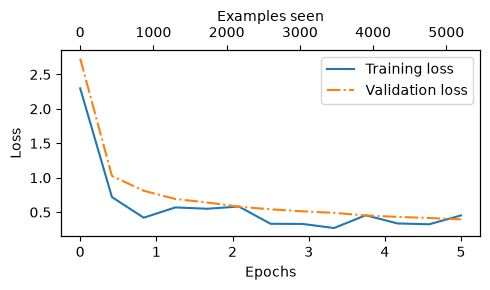

In [63]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))

plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses)

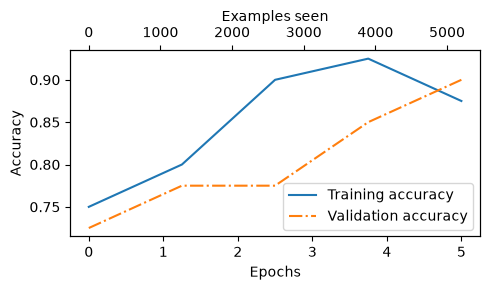

In [64]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_accs))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_accs))

plot_values(epochs_tensor, examples_seen_tensor, train_accs, val_accs, label="accuracy")

In [65]:
train_accuracy = calc_accuracy_loader(train_loader, model, device)
val_accuracy = calc_accuracy_loader(val_loader, model, device)
test_accuracy = calc_accuracy_loader(test_loader, model, device)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 87.69%
Validation accuracy: 89.26%
Test accuracy: 86.67%


# USING THE LLM AS A SPAM CLASSIFIER : use model on new Data

In [66]:
def classify_review(text, model, tokenizer, device, max_length=None, pad_token_id=50256):
    model.eval()

    # Prepare inputs to the model
    input_ids = tokenizer.encode(text)
    supported_context_length = model.pos_emb.weight.shape[0] #(context_length*embedding_dim)
    # Note: In the book, this was originally written as pos_emb.weight.shape[1] by mistake
    # It didn't break the code but would have caused unnecessary truncation (to 768 instead of 1024)

    # Truncate sequences if they too long
    input_ids = input_ids[:min(max_length, supported_context_length)]

    # Pad sequences to the longest sequence
    input_ids += [pad_token_id] * (max_length - len(input_ids))
    input_tensor = torch.tensor(input_ids, device=device).unsqueeze(0) # add batch dimension

    # Model inference
    with torch.no_grad():
        logits = model(input_tensor)[:, -1, :]  # Logits of the last output token
    predicted_label = torch.argmax(logits, dim=-1).item()

    # Return the classified result
    return "spam" if predicted_label == 1 else "not spam"

In [67]:
text_1 = (
    "You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award."
)

print(classify_review(
    text_1, model, tokenizer, device, max_length=train_dataset.max_length
))

spam


In [68]:
text_2 = (
    "Hey, just wanted to check if we're still on"
    " for dinner tonight? Let me know!"
)

print(classify_review(
    text_2, model, tokenizer, device, max_length=train_dataset.max_length
))

not spam


### save the model

In [92]:
torch.save(model.state_dict(), "review_classifier.pth")

In [94]:
model_state_dict = torch.load(
    "review_classifier.pth",
    map_location=device
)

model.load_state_dict(model_state_dict)
model.to(device)
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNormalization()
      (norm2): LayerNormalization()
      (drop_shortcuts): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): L

# FINETUNNING FOR "INSTRUCTIONS" DATASET MODEL

## Step1: Prepare the Dataset

In [74]:
import json
import os
import urllib
import ssl

def download_and_load_file(file_path, url):
    ssl_context = ssl.create_default_context()
    ssl_context.check_hostname = False
    ssl_context.verify_mode = ssl.CERT_NONE

    if not os.path.exists(file_path):
        with urllib.request.urlopen(url, context=ssl_context) as response:
            text_data = response.read().decode("utf-8")
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)
    else:
        with open(file_path, "r", encoding="utf-8") as file:
            text_data = file.read()

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    return data


file_path = "instruction-data.json"
url = (
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)

data = download_and_load_file(file_path, url)
print("Number of entries:", len(data))

Number of entries: 1100


In [75]:
print("Example entry:\n", data[50])

Example entry:
 {'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}


In [76]:
print("Another example entry:\n", data[999])

Another example entry:
 {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}


## Converting the Instructions to ALPACA FORMAT
**Alpaca Format**
Below is an instruction that describes a task. Write a response that appropriately completes the request.

!! instruction

!! input 

!!responce/output



In [96]:
def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    ) # this is a alpaca formate given by stanford 
    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""
    return instruction_text + input_text
"""Some tasks need extra input; others do not.
- If entry["input"] contains text, it adds an ### Input: section.
- If it is empty, it adds nothing.
"""


'Some tasks need extra input; others do not.\n- If entry["input"] contains text, it adds an ### Input: section.\n- If it is empty, it adds nothing.\n'

In [97]:
model_input = format_input(data[50])
desired_response = f"\n\n### Response:\n{data[50]['output']}"

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


In [98]:
model_input = format_input(data[999])
desired_response = f"\n\n### Response:\n{data[999]['output']}"

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is an antonym of 'complicated'?

### Response:
An antonym of 'complicated' is 'simple'.


## SPLITTING DATASET INTO TRAIN-TEST-VALIDATION

In [99]:
train_portion = int(len(data)*0.85) # 85% for training 
test_portion = int(len(data)*0.1) # 10% for testing 
val_portion = len(data) - train_portion - test_portion # remaining 5% 

train_data = data[:train_portion]
test_data = data[train_portion:train_portion+test_portion]
val_data = data[train_portion+test_portion:]


print("Training set length:", len(train_data))
print("Validation set length:", len(val_data))
print("Test set length:", len(test_data))

Training set length: 935
Validation set length: 55
Test set length: 110


## STEP 2: ORGANIZING DATA INTO TRAINING BATCHES

In [165]:
import torch
from torch.utils.data import Dataset,DataLoader

class InstructionDataset(Dataset):
    def __init__(self,data,tokenizer):
        self.data = data 
        # pre_tokenize 
        self.encoded_text = []
        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response: \n{entry['output']}"
            full_text = instruction_plus_input + response_text
            self.encoded_text.append(
                tokenizer.encode(full_text)
            )
    def __getitem__(self,index):
        return self.encoded_text[index]
    def __len__(self):
                return len(self.data)

In [101]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")

print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

[50256]


In [102]:
def custom_collate_draft_1(batch,pad_token_id=50256,device="cpu"):
    # find logest seq in batch
    # increase the max length by +1 which will add one extra padding token below

    batch_max_length = max(len(item)+1 for item in batch)

    # pad and prepare input
    input_lst = []
    for item in batch:
        new_item = item.copy()
        # add eos token 
        new_item+=[pad_token_id]
        # pad sequence to batch_max_length
        padded = (
            new_item + [pad_token_id]*(batch_max_length - len(new_item))
        )
        
        # Via padded[:-1], we remove the extra padded token
        # that has been added via the +1 setting in batch_max_length
        # (the extra padding token will be relevant in later codes)
        inputs = torch.tensor(padded[:-1])
        input_lst.append(inputs)

    # convert list of inputs to tensor and transfer to target devices 
    input_tensor = torch.stack(input_lst).to(device)
    return input_tensor

In [103]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]

batch = (
    inputs_1,
    inputs_2,
    inputs_3
)

print(custom_collate_draft_1(batch))

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])


In [104]:
# creating target token ids for the llm
def custom_collate_draft_2(batch,pad_token_id=50256,device="cpu"):
    batch_max_length = max(len(item)+1 for item in batch)

    # pad and prepare input 
    input_lst , target_lst = [],[]

    for item in batch:
        new_item = item.copy()
        # add eos token to the new item 
        new_item+=[pad_token_id]
        # pad seq to max_length
        padded = new_item + [pad_token_id]*(batch_max_length-len(new_item))

        inputs = torch.tensor(padded[:-1]) # truncate the last token for input 
        targets = torch.tensor(padded[1:]) # shift +1 to the right for target
        input_lst.append(inputs)
        target_lst.append(targets)

    # conver tlist of inputs to tensor and transfer to target device 
    input_tensor = torch.stack(input_lst).to(device)
    target_tensor = torch.stack(target_lst).to(device)
    return input_tensor,target_tensor

In [105]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]

batch = (
    inputs_1,
    inputs_2,
    inputs_3
)

inputs, targets = custom_collate_draft_2(batch)
print(inputs)
print(targets)


tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256, 50256, 50256, 50256],
        [    8,     9, 50256, 50256, 50256]])


In [166]:
"""In the next step, we assign a -100 placeholder value to all padding tokens.

This special value allows us to exclude these padding tokens from contributing to the training loss
calculation, ensuring that only meaningful data influences model learning.

In classification fine-tuning, we did not have to worry about this since we only trained the model
based on the last output token.

In the following code, we modify our custom collate function to replace tokens with ID 50256 with 
-100 in the target lists.

Additionally, we introduce an allowed_max_length parameter to optionally limit the length of the
samples.

This adjustment will be useful if you plan to work with your own datasets that exceed the 
1024- token context size supported by the GPT-2 model.

The code for this updated collate function is as follows:
"""

def custom_collate_fn(batch,pad_token_id=50256,ignore_index=-100,allowed_max_length = None,device="cpu"):
    # find the max batch length 
    batch_max_length = max(len(item)+1 for item in batch)

    # pad and prepare the input
    inputs_lst , targets_lst = [],[]

    for item in batch:
        new_item = item.copy()
        # add eos 
        new_item+=[pad_token_id]
        # pad sequence to max_length 
        padded = new_item + [pad_token_id]*(batch_max_length - len(new_item))
        inputs = torch.tensor(padded[:-1])
        targets = torch.tensor(padded[1:])

        # New: Replace all but the first padding tokens in targets by ignore_index
        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index
        # optional truncate to max_length 
        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # convert list of inputs and target to tensors and transfer to target device 
    inputs_tensor = torch.stack(inputs_lst).to(device)
    target_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor,target_tensor

In [107]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]
batch = (
    inputs_1,
    inputs_2,
    inputs_3
)

inputs, targets = custom_collate_fn(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])


In [108]:
logits_1 = torch.tensor(
    [[-1.0, 1.0],  # 1st training example
     [-0.5, 1.5]]  # 2nd training example
)
targets_1 = torch.tensor([0, 1])


loss_1 = torch.nn.functional.cross_entropy(logits_1, targets_1)
print(loss_1)

tensor(1.1269)


In [109]:
import torch

In [110]:
logits_2 = torch.tensor(
    [[-1.0, 1.0],
     [-0.5, 1.5],
     [-0.5, 1.5]]  # New 3rd training example
)
targets_2 = torch.tensor([0, 1, 1])

loss_2 = torch.nn.functional.cross_entropy(logits_2, targets_2)
print(loss_2)

tensor(0.7936)


In [111]:
logits_2 = torch.tensor(
    [[-1.0, 1.0],
     [-0.5, 1.5],
     [-0.5, 1.5]]  # New 3rd training example
)

targets_3 = torch.tensor([0, 1, -100]) # -100 means “do not calculate loss for this position.”

loss_3 = torch.nn.functional.cross_entropy(logits_2, targets_3)
print(loss_3)
print("loss_1 == loss_3:", loss_1 == loss_3)

tensor(1.1269)
loss_1 == loss_3: tensor(True)


## Creating the DataLoader Fuction here for the instruction dataset

In [178]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


if torch.cuda.is_available():
   device = torch.device("cuda")
elif torch.backends.mps.is_available():
   device = torch.device("mps")
else:
   device = torch.device("cpu")

print("Device:", device)

Device: mps


<div class="alert alert-block alert-success">

Next, to reuse the chosen device setting in custom_collate_fn when we plug it into the
PyTorch DataLoader class later in this section, we use the partial function from Python's
functools standard library to create a new version of the function with the device
argument pre-filled.

Additionally, we set the allowed_max_length to 1024, which truncates
the data to the maximum context length supported by the GPT-2 model we finetune later in
this chapter:
</div>

In [168]:
# direct passing of the fucntion we use the partial function 
# we must use the collate func --> variable data , vaibale size image 
from functools import partial 
customized_collate_fn = partial(custom_collate_fn,device=device,allowed_max_length = 1024)

In [169]:
from torch.utils.data import DataLoader,Dataset

num_workers = 0
batch_size = 8

torch.manual_seed(123)

train_dataset = InstructionDataset(train_data,tokenizer)
train_loader = DataLoader(
    train_dataset,batch_size= batch_size,collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)
val_dataset = InstructionDataset(val_data, tokenizer)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

test_dataset = InstructionDataset(test_data, tokenizer)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

In [116]:
print("Train loader:")
for inputs, targets in train_loader:
    print(inputs.shape, targets.shape)

Train loader:
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 77]) torch.Size([8, 77])
torch.Size([8, 74]) torch.Size([8, 74])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 66]) torch.Size([8, 66])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 81]) torch.Size([8, 81])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 63]) torch.Size([8, 63])
torch.Size([8, 76]) torch.Size([8, 76])
torch.Size([8, 63]) torch.Size([8, 63])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 78]) torch.Size([8, 78])
torch.Size([8, 70]) torch.Size([8, 70])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 84]) torch.Size([8, 84])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 81]) torch.Size([8, 81])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 70]) torch.Size([8, 70])
torch.Size([8, 66]) torch.Size([8, 66])
torch.Size([8, 69]) torch.

<div class="alert alert-block alert-success">
In the preceding output, we can see that the first input and target batch have dimensions 8×61, where 8 represents the batch size, and 61 is the number of tokens in each training example in this batch.

The second input and target batch have a different number of tokens, for instance, 76.

As we saw in the preceding code output, thanks to our custom collate function, the data loader is able to create batches of different lengths.

In the next section, we load a pretrained LLM that we can then finetune with this data loader.
</div>

## Loading A Pre-Trained LLM

In [117]:
from gpt_download3 import download_and_load_gpt2
BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

# kya-kya model configeration hai 
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

CHOOSE_MODEL = "gpt2-medium (355M)" # hamlog konsa model le rhe hai

# updatet the base config with the new chossen model 
BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")") # extract from the choose_model
# downlod the setting and the params 
settings, params = download_and_load_gpt2(
    model_size=model_size,
    models_dir="gpt2"
)

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

checkpoint: 100%|████████████████████████████████████████████████████████████████████| 77.0/77.0 [00:00<00:00, 325kB/s]


encoder.json: 100%|███████████████████████████████████████████████████████████████| 1.04M/1.04M [00:10<00:00, 96.7kB/s]


hparams.json: 100%|██████████████████████████████████████████████████████████████████| 91.0/91.0 [00:00<00:00, 508kB/s]


model.ckpt.data-00000-of-00001: 100%|█████████████████████████████████████████████| 1.42G/1.42G [07:44<00:00, 3.05MB/s]


model.ckpt.index: 100%|███████████████████████████████████████████████████████████| 10.4k/10.4k [00:00<00:00, 45.1MB/s]


model.ckpt.meta: 100%|██████████████████████████████████████████████████████████████| 927k/927k [00:10<00:00, 84.3kB/s]


vocab.bpe: 100%|████████████████████████████████████████████████████████████████████| 456k/456k [00:05<00:00, 90.8kB/s]


In [170]:
torch.manual_seed(123)
input_text = format_input(val_data[0])

print(input_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'


In [119]:
def generate(model,idx,max_new_tokens,context_size,temperature=0.0,top_k=None,eos_id=None):
    # get the logits and focus on the last step
    for _ in range(max_new_tokens):
        idx_cond = idx[:,-context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:,-1,:]

        # filter logits with top k sampling 
        if top_k is not None:
            # keep only the top k values --> torch.topk= = logits_top , logits_ids
            top_logits, _ = torch.topk(logits,top_k)
            min_val = top_logits[:, -1:]
            # set the logtis to -inf whose value is less then min_val_logits
            logits = torch.where(logits<min_val , torch.tensor(float("-inf")).to(logits.device),logits)

        # apply temp scalling 
        if temperature > 0.0:
            logits = logits/temperature
            # apply softmax  to get probabilities
            probas = torch.softmax(logits,dim=-1) #(batch_size,context_length)
            # aply multinomial sample from the distribution 
            idx_next = torch.multinomial(probas,num_samples=1)#(batch_size,1)
            
        # Otherwise same as before: get idx of the vocab entry with the highest logits value
        else:
            idx_next = torch.argmax(logits,dim=-1,keepdim=True)
            
        if idx_next==eos_id: # # Stop generating early if end-of-sequence token is encountered and eos_id is specified
            break
    
    
        idx = torch.cat((idx,idx_next),dim=1)

    return idx 

In [179]:
token_ids = generate(
    model=model,
    idx=text_to_token(input_text, tokenizer).to(device),
    max_new_tokens=35,
    context_size=BASE_CONFIG["context_length"],
    eos_id=50256,
)

generated_text = token_to_text(token_ids, tokenizer)

In [180]:
response_text = generated_text[len(input_text):].strip()
print(response_text)

, the most of the most of the most of the most of the most of the most of the


##  FINETUNING THE LLM ON INSTRUCTION DATA

In [181]:
# loss batch and loss loader 
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0,1),
                                             target_batch.flatten())
    return loss
    
def calc_loss_loader(data_loader, model, device, num_batches):
    total_loss = 0 
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # reduce the num of batches to total num batches in data loader 
        # if num_batches exceed the number of batches in the data loader then use the max_len of data_loader
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = BASE_CONFIG["context_length"]
    encoded = text_to_token(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))
    model.train()

def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                      eval_freq, eval_iter, start_context, tokenizer):
    # Initialize lists to track losses and tokens seen
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    # main training loop 
    for epoch in range(num_epochs):
        model.train()

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()  # Reset loss gradients from previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()         # Calculate loss gradients
            optimizer.step()        # Update model weights using loss gradients
            # numel function returns the total num of elements 
            tokens_seen += input_batch.numel()  # Returns the total number of elements (or tokens) in the input_batch.
            global_step += 1

            # optional eval step 
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # print a sample text after each epoch 
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )
    return train_losses, val_losses, track_tokens_seen


In [182]:
def evaluate_model(model,train_loader,val_loader,device,eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader,model,device,num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss,val_loss

In [186]:
model.to(device)

torch.manual_seed(123)

with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
    val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 1.0764992833137512
Validation loss: 1.2058085441589355


In [189]:
import time

start_time = time.time()

torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)

num_epochs = 1

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context=format_input(val_data[0]), tokenizer=tokenizer
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss nan, Val loss nan
Ep 1 (Step 000005): Train loss nan, Val loss nan
Ep 1 (Step 000010): Train loss nan, Val loss nan
Ep 1 (Step 000015): Train loss nan, Val loss nan
Ep 1 (Step 000020): Train loss nan, Val loss nan
Ep 1 (Step 000025): Train loss nan, Val loss nan
Ep 1 (Step 000030): Train loss nan, Val loss nan
Ep 1 (Step 000035): Train loss nan, Val loss nan
Ep 1 (Step 000040): Train loss nan, Val loss nan
Ep 1 (Step 000045): Train loss nan, Val loss nan
Ep 1 (Step 000050): Train loss nan, Val loss nan
Ep 1 (Step 000055): Train loss nan, Val loss nan
Ep 1 (Step 000060): Train loss nan, Val loss nan
Ep 1 (Step 000065): Train loss nan, Val loss nan
Ep 1 (Step 000070): Train loss nan, Val loss nan
Ep 1 (Step 000075): Train loss nan, Val loss nan
Ep 1 (Step 000080): Train loss nan, Val loss nan
Ep 1 (Step 000085): Train loss nan, Val loss nan
Ep 1 (Step 000090): Train loss nan, Val loss nan
Ep 1 (Step 000095): Train loss nan, Val loss nan
Ep 1 (Step 000100): 

<div class="alert alert-block alert-info">


As we can see based on the outputs above, the model trains well, as we can tell based on the decreasing training loss and validation loss values.
    
Furthermore, based on the response text printed after each epoch, we can see that the model almost correctly follows the instruction to convert the input sentence 'The chef cooks the meal every day.' into passive voice 'The meal is prepared every day by the chef.' (We will properly format and evaluate the responses in a later section.

To get better results, we need to finetune the model for more epochs.

Finally, let's take a look at the training and validation loss curves

</div>

In [190]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  # only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(tokens_seen, train_losses, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig("loss-plot.pdf")
    plt.show()

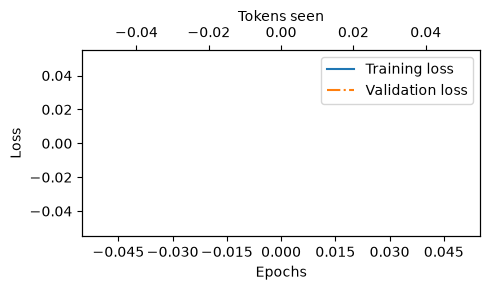

In [196]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)